<a href="https://colab.research.google.com/github/moysessevan/termodinamica-python/blob/main/cod_2_4_diagrama_Ph_r134a.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

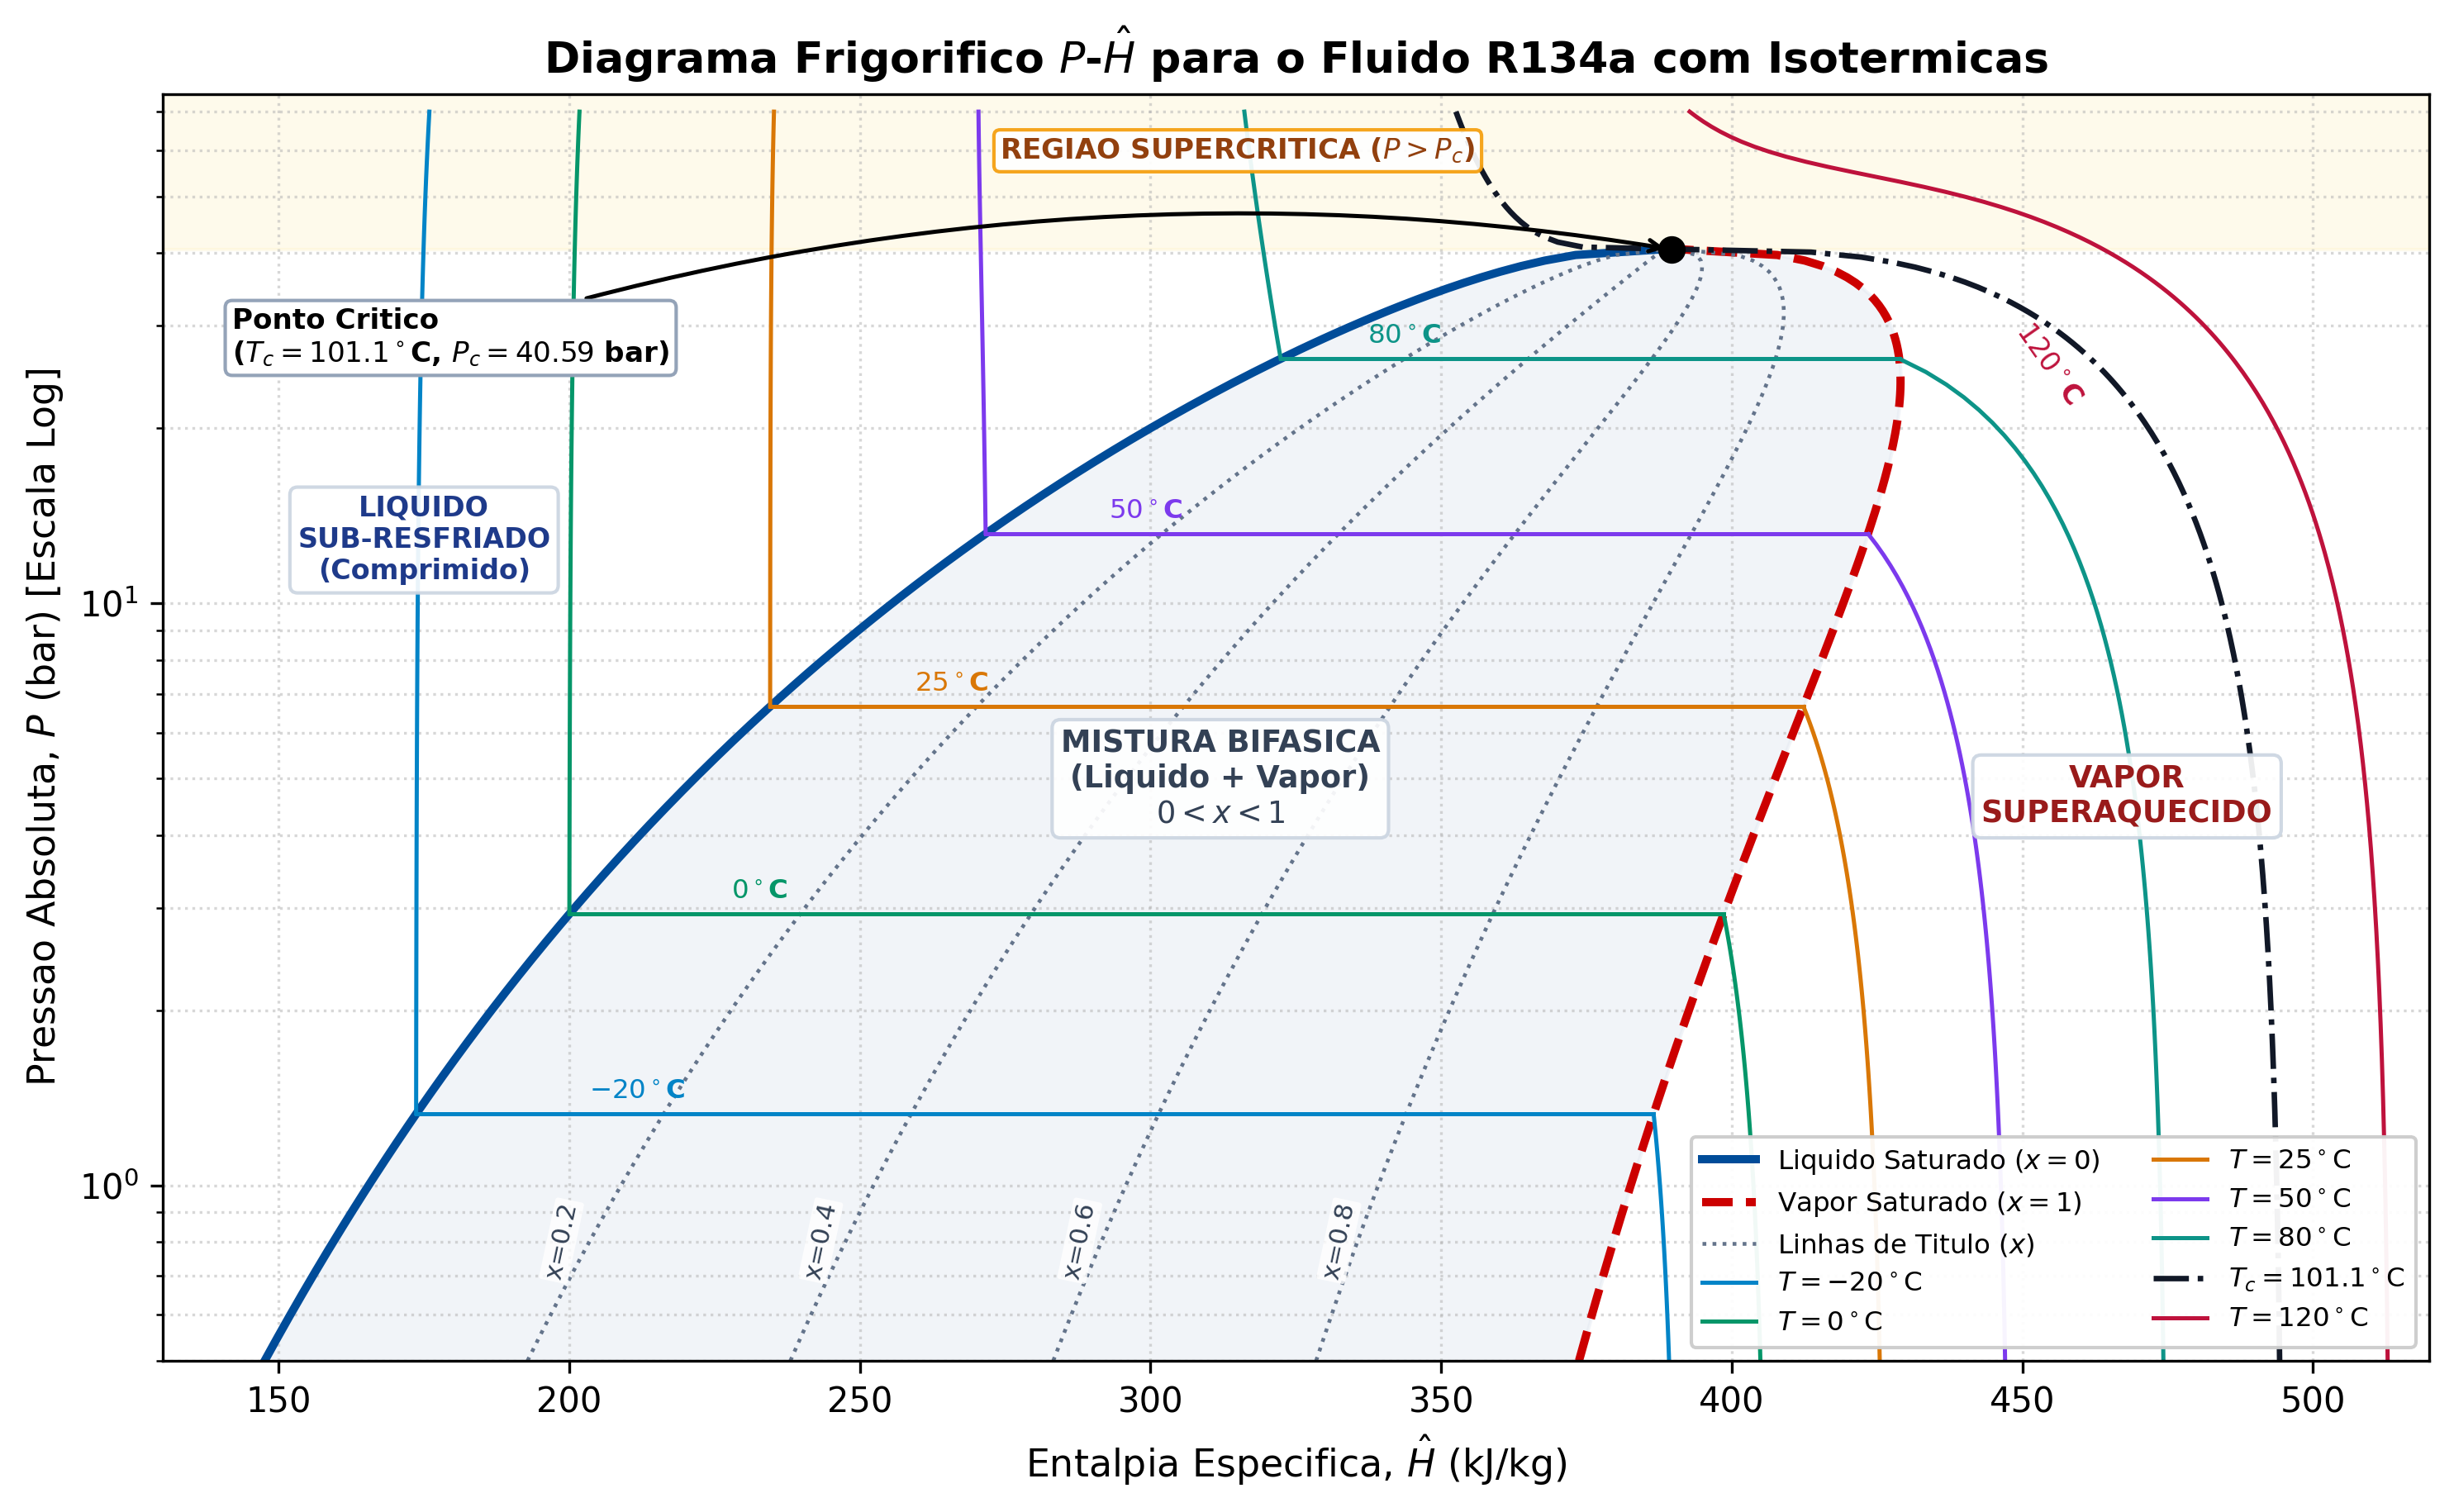

In [2]:
!pip install CoolProp --quiet

import numpy as np
import matplotlib.pyplot as plt
from CoolProp.CoolProp import PropsSI

# Diagrama P-H para o fluido refrigerante R134a
ref = 'R134a'
P_c = PropsSI('Pcrit', ref)
T_c = PropsSI('Tcrit', ref)
rho_c = PropsSI('rhocrit', ref)
h_c = PropsSI('H', 'T', T_c, 'D', rho_c, ref) / 1000.0  # kJ/kg
P_min = 0.5e5  # 0.5 bar (cobre aplicacoes tipicas de refrigeracao)

p_vet = np.logspace(np.log10(P_min), np.log10(P_c - 500), 200)
hf_vet = np.array([PropsSI('H', 'P', p, 'Q', 0, ref) / 1000.0 for p in p_vet])
hg_vet = np.array([PropsSI('H', 'P', p, 'Q', 1, ref) / 1000.0 for p in p_vet])

fig, ax = plt.subplots(figsize=(10, 6.2), dpi=300)

# 1. Domo de Saturacao
ax.plot(hf_vet, p_vet / 1e5, color='#004c99', linewidth=2.4, label=r'Liquido Saturado ($x=0$)')
ax.plot(hg_vet, p_vet / 1e5, color='#cc0000', linestyle='--', linewidth=2.4, label=r'Vapor Saturado ($x=1$)')
ax.fill_betweenx(p_vet / 1e5, hf_vet, hg_vet, color='#e2e8f0', alpha=0.45)

# 2. Linhas de Titulo Constante (x = 0.2, 0.4, 0.6, 0.8) dentro do envelope
titulos = [0.2, 0.4, 0.6, 0.8]
for x in titulos:
    hx_vet = hf_vet + x * (hg_vet - hf_vet)
    ax.plot(hx_vet, p_vet / 1e5, color='#64748b', linestyle=':', linewidth=1.1,
            label=r'Linhas de Titulo ($x$)' if x == 0.2 else "")
    idx_rot = 12
    ax.text(hx_vet[idx_rot], (p_vet[idx_rot] / 1e5) * 1.05, f'x={x:.1f}', fontsize=7.5,
            color='#334155', ha='center', va='bottom', rotation=78,
            bbox=dict(boxstyle='round,pad=0.1', facecolor='white', edgecolor='none', alpha=0.8))

# 3. Linhas Isotermicas (Subcriticas, Critica e Supercritica)
isotermas_C = [-20, 0, 25, 50, 80, T_c - 273.15, 120]
cores_iso = ['#0284c7', '#059669', '#d97706', '#7c3aed', '#0d9488', '#111827', '#be123c']

for T_val_C, cor in zip(isotermas_C, cores_iso):
    T_k = T_val_C + 273.15
    eh_critica = abs(T_k - T_c) < 0.2
    estilo = '-.' if eh_critica else '-'
    largura = 1.6 if eh_critica else 1.2
    rotulo_t = rf'$T_c = {T_val_C:.1f}^\circ$C' if eh_critica else rf'$T = {int(T_val_C)}^\circ$C'

    if T_k < T_c:
        P_s = PropsSI('P', 'T', T_k, 'Q', 0, ref)
        hf_s = PropsSI('H', 'T', T_k, 'Q', 0, ref) / 1000.0
        hg_s = PropsSI('H', 'T', T_k, 'Q', 1, ref) / 1000.0

        # Trecho liquido sub-resfriado
        P_liq = np.geomspace(P_s * 1.002, 70e5, 60)
        h_liq = [PropsSI('H', 'T', T_k, 'P', p, ref) / 1000.0 for p in P_liq]

        # Trecho patamar bifasico
        h_pat = [hf_s, hg_s]
        P_pat = [P_s, P_s]

        # Trecho vapor superaquecido
        P_vap = np.geomspace(P_min, P_s * 0.998, 80)
        h_vap = [PropsSI('H', 'T', T_k, 'P', p, ref) / 1000.0 for p in P_vap]

        ax.plot(h_liq, P_liq / 1e5, color=cor, linestyle=estilo, linewidth=largura)
        ax.plot(h_pat, np.array(P_pat) / 1e5, color=cor, linestyle=estilo, linewidth=largura, label=rotulo_t)
        ax.plot(h_vap, P_vap / 1e5, color=cor, linestyle=estilo, linewidth=largura)

        # Rotulo direto sobre o patamar bifasico
        h_mid = hf_s + 0.14 * (hg_s - hf_s)
        ax.text(h_mid, (P_s / 1e5) * 1.06, rf'${int(T_val_C)}^\circ$C',
                color=cor, fontsize=7.8, fontweight='bold')
    else:
        # Isoterma critica ou supercritica
        P_sup = np.geomspace(P_min, 70e5, 250)
        h_sup = [PropsSI('H', 'T', T_k, 'P', p, ref) / 1000.0 for p in P_sup]
        ax.plot(h_sup, P_sup / 1e5, color=cor, linestyle=estilo, linewidth=largura, label=rotulo_t)
        if not eh_critica:
            ax.text(448, 22, rf'${int(T_val_C)}^\circ$C', color=cor, fontsize=8, fontweight='bold', rotation=-55)

# 4. Ponto Critico (deslocado para baixo, fora da faixa supercritica)
ax.plot(h_c, P_c / 1e5, 'ko', markersize=7, zorder=6)
ax.annotate(rf'Ponto Critico' + '\n' + rf'($T_c={T_c-273.15:.1f}^\circ$C, $P_c={P_c/1e5:.2f}$ bar)',
            xy=(h_c, P_c / 1e5), xytext=(142, 26),
            fontsize=8.2, fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.25', facecolor='white', edgecolor='#94a3b8'),
            arrowprops=dict(arrowstyle='->', color='black', lw=1.2, connectionstyle='arc3,rad=-0.12'),
            zorder=7)

# 5. Identificacao das Regioes Termodinamicas
estilo_regiao = dict(boxstyle='round,pad=0.28', facecolor='white', edgecolor='#cbd5e1', alpha=0.92)

ax.text(175, 11, 'LIQUIDO\nSUB-RESFRIADO\n(Comprimido)', fontsize=8,
        fontweight='bold', color='#1e3a8a', ha='center', bbox=estilo_regiao)

ax.text(312, 4.2, 'MISTURA BIFASICA\n(Liquido + Vapor)\n$0 < x < 1$', fontsize=8.8,
        fontweight='bold', color='#334155', ha='center', bbox=estilo_regiao)

ax.text(468, 4.2, 'VAPOR\nSUPERAQUECIDO', fontsize=8.8,
        fontweight='bold', color='#991b1b', ha='center', bbox=estilo_regiao)

ax.axhspan(P_c / 1e5, 75, color='#fef3c7', alpha=0.35, zorder=0)
ax.text(315, 58, 'REGIAO SUPERCRITICA ($P > P_c$)', fontsize=8.2,
        fontweight='bold', color='#92400e', ha='center',
        bbox=dict(boxstyle='round,pad=0.22', facecolor='white', edgecolor='#f59e0b', alpha=0.92))

# Configuracoes finais dos eixos
ax.set_yscale('log')
ax.set_xlim(130, 520)
ax.set_ylim(0.5, 75)
ax.set_xlabel(r'Entalpia Especifica, $\hat{H}$ ($\mathrm{kJ/kg}$)', fontsize=11)
ax.set_ylabel(r'Pressao Absoluta, $P$ ($\mathrm{bar}$) [Escala Log]', fontsize=11)
ax.set_title(rf'Diagrama Frigorifico $P$-$\hat{{H}}$ para o Fluido {ref} com Isotermicas', fontsize=12.5, fontweight='bold')
ax.grid(True, which='both', linestyle=':', alpha=0.5)
ax.legend(loc='lower right', fontsize=7.8, ncol=2, frameon=True, facecolor='white', framealpha=0.95)

plt.tight_layout()
plt.savefig('diagrama_ph_r134a.png', dpi=300)
plt.show()